In [1]:
import ast, glob, re, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
import lightgbm as lgb
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error

warnings.filterwarnings("ignore", message=".*eval_set.*")

DATA_DIR = "fe_outputs"
TARGET = "ClosePrice"
SEED = 42
MAX_TREES, EARLY_STOP = 1500, 100        # same as notebook 05

# how the best version of each model is chosen (validation only)
SELECT_BY = "val_MdAPE_%"
HIGHER_IS_BETTER = {"val_R2"}
sign = 1 if SELECT_BY in HIGHER_IS_BETTER else -1

TREE_RESULTS = "tree_forest_results.csv"  # notebook 04 (after FE)
GBM_RESULTS = "gbm_results.csv"           # notebook 05
BASELINE = "LinearRegression"

OUT_DIR = Path("evaluation_outputs")      # all CSVs from this notebook go here
OUT_DIR.mkdir(exist_ok=True)

N_BANDS = 5          # price bands (5 = quintiles)
N_BOOT = 1000        # bootstrap resamples

In [2]:
def n_months(path):
    return int(re.search(r"train_(\d+)m", str(path)).group(1))

split_dirs = sorted(glob.glob(f"{DATA_DIR}/train_*m"), key=n_months)
print("windows:", [n_months(d) for d in split_dirs])

EXCLUDE_COLS = ["CloseDate"]

def load_split(folder):
    """Same feature prep as notebooks 03-05: numeric features, no dates, NaN -> train median."""
    train = pd.read_csv(f"{folder}/features_train.csv")
    val = pd.read_csv(f"{folder}/features_val.csv")
    test = pd.read_csv(f"{folder}/features_test.csv")
    banned = [c for c in train.columns if c in EXCLUDE_COLS or "date" in c.lower()]
    feats = train.drop(columns=[TARGET] + banned).select_dtypes(include="number").columns
    X_tr, X_val, X_te = (df[feats].replace([np.inf, -np.inf], np.nan) for df in (train, val, test))
    med = X_tr.median()
    return X_tr.fillna(med), train[TARGET], X_val.fillna(med), val[TARGET], X_te.fillna(med), test[TARGET]

def metrics(y_true, y_pred, y_train):
    """Regression metrics. y_train is only used for the MASE scale."""
    y_true, y_pred, y_train = (np.asarray(a, dtype=float) for a in (y_true, y_pred, y_train))
    err = np.abs(y_pred - y_true)
    ape = err / y_true
    mse = mean_squared_error(y_true, y_pred)

    # sMAPE (%): symmetric, bounded 0-200%
    denom = np.abs(y_true) + np.abs(y_pred)
    smape = np.where(denom == 0, 0.0, 2 * err / np.where(denom == 0, 1, denom))

    # MASE: MAE / train-set MAE of "predict the train median price". < 1 beats that naive guess.
    naive_mae = np.mean(np.abs(y_train - np.median(y_train)))

    return {
        "R2": r2_score(y_true, y_pred),
        "MAPE_%": ape.mean() * 100,
        "MdAPE_%": np.median(ape) * 100,
        "sMAPE_%": smape.mean() * 100,
        "MAE_$": err.mean(),
        "MSE_$2": mse,
        "RMSE_$": np.sqrt(mse),
        "MASE": err.mean() / naive_mae,
        "PPE10_%": (ape <= 0.10).mean() * 100,     # share of homes predicted within 10% of the sale price
    }

# predicts in dollars even with a log target (same as notebook 05)
class GBM:
    def __init__(self, model, log_target):
        self.model, self.log_target = model, log_target
    def predict(self, X):
        pred = self.model.predict(X)
        return np.exp(pred) if self.log_target else pred

def fit_gbm(name, params, X_tr, y_tr, X_val, y_val):
    params = dict(params)
    log_target = params.pop("log_target")
    y_fit, y_eval = (np.log(y_tr), np.log(y_val)) if log_target else (y_tr, y_val)
    if name == "LightGBM":
        model = lgb.LGBMRegressor(n_estimators=MAX_TREES, subsample_freq=1,
                                  random_state=SEED, n_jobs=-1, verbose=-1, **params)
        model.fit(X_tr, y_fit, eval_set=[(X_val, y_eval)],
                  callbacks=[lgb.early_stopping(EARLY_STOP, verbose=False)])
    else:
        model = xgb.XGBRegressor(n_estimators=MAX_TREES, tree_method="hist",
                                 early_stopping_rounds=EARLY_STOP,
                                 random_state=SEED, n_jobs=-1, **params)
        model.fit(X_tr, y_fit, eval_set=[(X_val, y_eval)], verbose=False)
    return GBM(model, log_target)

windows: [6, 9, 12, 15, 18, 21, 24, 27, 30]


## Pick the best version of each model

For each model, the training window (and saved grid-search hyperparameters) with the best validation score. The Linear Regression baseline has no hyperparameters, so it is fit on every window here and the best window is chosen the same way.

In [3]:
def best_rows(path):
    df = pd.read_csv(path)
    if "dataset" in df.columns:
        df = df[df["dataset"] == "after_fe"]
    missing = {"model", "n_train_months", "best_params", SELECT_BY} - set(df.columns)
    if missing:
        raise ValueError(f"{path} is missing {sorted(missing)}; re-run the notebook that makes it")
    pick = df.groupby("model")[SELECT_BY].idxmax() if SELECT_BY in HIGHER_IS_BETTER else df.groupby("model")[SELECT_BY].idxmin()
    return df.loc[pick]

chosen = pd.concat([best_rows(TREE_RESULTS), best_rows(GBM_RESULTS)], ignore_index=True)
chosen["params"] = chosen["best_params"].apply(ast.literal_eval)
chosen[["model", "n_train_months", SELECT_BY]]

,model,n_train_months,val_MdAPE_%
0,DecisionTree,27,9.545046
1,RandomForest,27,7.680756
2,LightGBM,30,7.067761
3,XGBoost,30,7.075260


In [4]:
BASE_MODELS = {
    "DecisionTree": lambda: DecisionTreeRegressor(random_state=SEED),
    "RandomForest": lambda: RandomForestRegressor(random_state=SEED, n_jobs=-1),
}

preds, rows = {}, []
y_test = None

def record(name, months, params, y_tr, y_val, y_te, val_pred, te_pred):
    global y_test
    val_pred, te_pred = np.asarray(val_pred), np.asarray(te_pred)
    preds[name] = {"val": val_pred, "test": te_pred}
    y_test = np.asarray(y_te, dtype=float)
    rows.append({
        "model": name, "n_train_months": months, "params": str(params),
        **{f"val_{k}": v for k, v in metrics(y_val, val_pred, y_tr).items()},
        "val_neg_preds": int((val_pred <= 0).sum()),
        **{f"test_{k}": v for k, v in metrics(y_te, te_pred, y_tr).items()},
        "neg_preds": int((te_pred <= 0).sum()),
    })

# baseline: linear regression on every window, keep the best on validation
best_lr = None
for folder in split_dirs:
    months = n_months(folder)
    X_tr, y_tr, X_val, y_val, X_te, y_te = load_split(folder)
    lr = LinearRegression().fit(X_tr, y_tr)
    val_pred, te_pred = lr.predict(X_val), lr.predict(X_te)
    score = metrics(y_val, val_pred, y_tr)[SELECT_BY.replace("val_", "", 1)]
    if best_lr is None or sign * score > best_lr[0]:
        best_lr = (sign * score, months, y_tr, y_val, y_te, val_pred, te_pred)
_, months, y_tr, y_val, y_te, val_pred, te_pred = best_lr
record(BASELINE, months, {}, y_tr, y_val, y_te, val_pred, te_pred)
print(f"{BASELINE}: {months}-month window")

# the other models: refit at their best window with the saved parameters (one at a time to save memory)
for _, r in chosen.iterrows():
    name, months, params = r["model"], int(r["n_train_months"]), r["params"]
    X_tr, y_tr, X_val, y_val, X_te, y_te = load_split(f"{DATA_DIR}/train_{months}m")
    if name in ("LightGBM", "XGBoost"):
        model = fit_gbm(name, params, X_tr, y_tr, X_val, y_val)
    else:
        model = BASE_MODELS[name]().set_params(**params).fit(X_tr, y_tr)
    record(name, months, params, y_tr, y_val, y_te, model.predict(X_val), model.predict(X_te))
    del model
    print(f"{name}: {months}-month window")

# sanity check: the refit should reproduce what the earlier notebooks saved
if "test_MdAPE_%" in chosen.columns:
    chk = pd.DataFrame(rows).set_index("model")["test_MdAPE_%"]
    diff = (chosen.set_index("model")["test_MdAPE_%"] - chk.reindex(chosen["model"]).values).abs()
    bad = diff[diff > 0.1]
    print("\nrefit matches saved results" if bad.empty else f"\nWARNING refit differs from saved test MdAPE (pp): {bad.round(3).to_dict()}")

LinearRegression: 27-month window
DecisionTree: 27-month window
RandomForest: 27-month window
LightGBM: 30-month window
XGBoost: 30-month window

refit matches saved results


## Metrics summary

Validation and test metrics for every model, sorted by validation score. Saved to `evaluation_outputs/metrics_summary.csv`.

In [5]:
summary = (pd.DataFrame(rows)
           .sort_values(SELECT_BY, ascending=SELECT_BY not in HIGHER_IS_BETTER)
           .reset_index(drop=True))
summary.insert(0, "rank_by_validation", range(1, len(summary) + 1))
summary.to_csv(OUT_DIR / "metrics_summary.csv", index=False)

order = summary["model"].tolist()        # best first; used for every table below
best_name = order[0]

show = ["model", "n_train_months", "val_MdAPE_%", "test_R2", "test_MAPE_%", "test_MdAPE_%", "test_sMAPE_%",
        "test_MAE_$", "test_RMSE_$", "test_MASE", "test_PPE10_%"]
summary[show].round(4)

,model,n_train_months,val_MdAPE_%,test_R2,test_MAPE_%,test_MdAPE_%,test_sMAPE_%,test_MAE_$,test_RMSE_$,test_MASE,test_PPE10_%
0,LightGBM,30,7.0678,0.8814,11.7665,7.2807,11.0805,166767.6101,456742.9173,0.2584,61.7265
1,XGBoost,30,7.0753,0.8756,11.7371,7.2705,11.0402,166252.6088,467818.4051,0.2576,62.0130
2,RandomForest,27,7.6808,0.8550,13.4554,8.0808,12.1731,186404.6621,504945.2530,0.2901,57.4962
3,DecisionTree,27,9.5450,0.7382,17.4415,9.9144,15.4604,247499.0996,678515.1832,0.3852,50.3820
4,LinearRegression,27,13.3737,0.7888,19.8090,14.0849,18.2561,251363.3567,609502.8350,0.3912,37.0225


## Is the improvement over the baseline real?

Paired bootstrap on the test set: resample the test homes, recompute each model's MdAPE on the same resample, and look at the difference. If the 95% interval excludes 0, the gap is not just noise.

In [6]:
ape = {m: np.abs(p["test"] - y_test) / y_test for m, p in preds.items()}
n_test = len(y_test)

rng = np.random.default_rng(SEED)
idx = rng.integers(0, n_test, size=(N_BOOT, n_test), dtype=np.int32)
boot = {m: np.median(a[idx], axis=1) * 100 for m, a in ape.items()}   # bootstrap MdAPE (%)

def compare(a, b):
    d = boot[a] - boot[b]
    lo, hi = np.percentile(d, [2.5, 97.5])
    base = np.median(ape[b]) * 100
    return {"model_a": a, "model_b": b,
            "MdAPE_diff_pp": np.median(ape[a]) * 100 - base,
            "relative_change_%": (np.median(ape[a]) * 100 - base) / base * 100,
            "ci_low": lo, "ci_high": hi, "excludes_zero": bool(lo > 0 or hi < 0)}

pairs = [compare(m, BASELINE) for m in order if m != BASELINE]
if len(order) > 1 and order[1] != BASELINE and best_name != BASELINE:
    pairs.append(compare(best_name, order[1]))        # best vs runner-up
boot_table = pd.DataFrame(pairs)
boot_table.to_csv(OUT_DIR / "bootstrap_vs_baseline.csv", index=False)
boot_table.round(3)

,model_a,model_b,MdAPE_diff_pp,relative_change_%,ci_low,ci_high,excludes_zero
0,LightGBM,LinearRegression,-6.804,-48.308,-7.113,-6.478,True
1,XGBoost,LinearRegression,-6.814,-48.381,-7.124,-6.482,True
2,RandomForest,LinearRegression,-6.004,-42.628,-6.320,-5.690,True
3,DecisionTree,LinearRegression,-4.170,-29.609,-4.508,-3.844,True
4,LightGBM,XGBoost,0.010,0.140,-0.129,0.152,False


## Error by price band

Test homes are split into equal-sized price bands. Bias is the median signed error (negative = the model under-predicts).

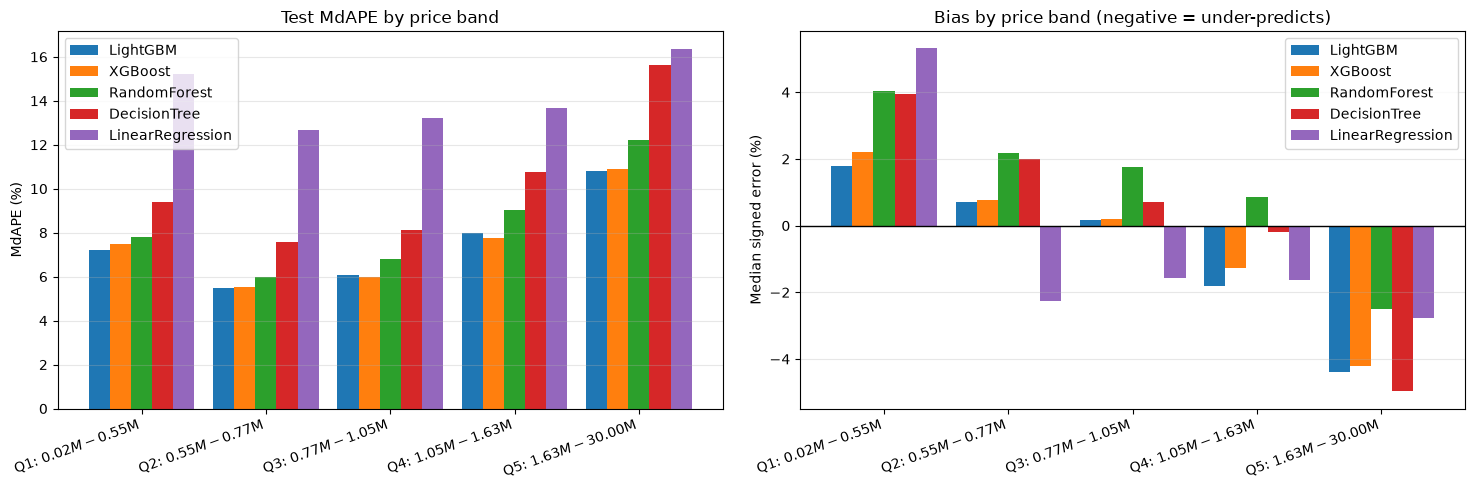

MdAPE (%)                                    \
                    LightGBM XGBoost RandomForest DecisionTree   
Q1: $0.02M-$0.55M       7.20    7.48         7.80         9.42   
Q2: $0.55M-$0.77M       5.47    5.54         5.99         7.58   
Q3: $0.77M-$1.05M       6.08    5.99         6.80         8.12   
Q4: $1.05M-$1.63M       7.97    7.76         9.02        10.74   
Q5: $1.63M-$30.00M     10.81   10.90        12.24        15.63   

                                    MAPE (%)                       \
                   LinearRegression LightGBM XGBoost RandomForest   
Q1: $0.02M-$0.55M             15.22    15.62   15.82        17.98   
Q2: $0.55M-$0.77M             12.68     8.70    8.64         9.77   
Q3: $0.77M-$1.05M             13.23     9.02    8.95        10.71   
Q4: $1.05M-$1.63M             13.65    11.01   10.89        12.58   
Q5: $1.63M-$30.00M            16.34    14.44   14.35        16.21   

                                                 bias (%)          \
                   DecisionTree LinearRegression LightGBM XGBoost   
Q1: $0.02M-$0.55M         23.32            27.98     1.78    2.21   
Q2: $0.55M-$0.77M         12.14            15.88     0.72    0.77   
Q3: $0.77M-$1.05M         13.43            16.87     0.17    0.20   
Q4: $1.05M-$1.63M         16.52            17.67    -1.82   -1.26   
Q5: $1.63M-$30.00M        21.74            20.62    -4.39   -4.21   

                                                               
                   RandomForest DecisionTree LinearRegression  
Q1: $0.02M-$0.55M          4.04         3.93             5.31  
Q2: $0.55M-$0.77M          2.17         1.99            -2.26  
Q3: $0.77M-$1.05M          1.77         0.72            -1.57  
Q4: $1.05M-$1.63M          0.85        -0.20            -1.62  
Q5: $1.63M-$30.00M        -2.50        -4.97            -2.76

In [7]:
edges = np.quantile(y_test, np.linspace(0, 1, N_BANDS + 1))
band = np.clip(np.searchsorted(edges, y_test, side="right") - 1, 0, N_BANDS - 1)
band_labels = [f"Q{i+1}: ${edges[i]/1e6:.2f}M-${edges[i+1]/1e6:.2f}M" for i in range(N_BANDS)]

signed = {m: (p["test"] - y_test) / y_test for m, p in preds.items()}

band_mdape = pd.DataFrame({m: pd.Series(ape[m] * 100).groupby(band).median() for m in order})
band_mape = pd.DataFrame({m: pd.Series(ape[m] * 100).groupby(band).mean() for m in order})
band_bias = pd.DataFrame({m: pd.Series(signed[m] * 100).groupby(band).median() for m in order})
for t in (band_mdape, band_mape, band_bias):
    t.index = band_labels

long = []
for i, lab in enumerate(band_labels):
    for m in order:
        mask = band == i
        long.append({"band": lab, "price_low": edges[i], "price_high": edges[i + 1], "n": int(mask.sum()),
                     "model": m, "MdAPE_%": band_mdape.loc[lab, m], "MAPE_%": band_mape.loc[lab, m],
                     "MAE_$": np.abs(preds[m]["test"][mask] - y_test[mask]).mean(), "bias_%": band_bias.loc[lab, m]})
pd.DataFrame(long).to_csv(OUT_DIR / "price_band_metrics.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
band_mdape.plot.bar(ax=axes[0], width=0.85)
axes[0].set(ylabel="MdAPE (%)", title="Test MdAPE by price band")
band_bias.plot.bar(ax=axes[1], width=0.85)
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set(ylabel="Median signed error (%)", title="Bias by price band (negative = under-predicts)")
for ax in axes:
    ax.grid(alpha=0.3, axis="y")
    ax.tick_params(axis="x", rotation=20)
    plt.setp(ax.get_xticklabels(), ha="right")
plt.tight_layout()
plt.show()

pd.concat({"MdAPE (%)": band_mdape, "MAPE (%)": band_mape, "bias (%)": band_bias}, axis=1).round(2)

## Insights

Generated from the results above.

In [8]:
best = summary.iloc[0]
lines = [f"Best model by validation {SELECT_BY}: {best['model']} ({int(best['n_train_months'])}-month window)",
         f"  test MdAPE {best['test_MdAPE_%']:.2f}%, MAPE {best['test_MAPE_%']:.2f}%, sMAPE {best['test_sMAPE_%']:.2f}%, "
         f"R² {best['test_R2']:.3f}, MAE ${best['test_MAE_$']:,.0f}, MASE {best['test_MASE']:.2f}, "
         f"{best['test_PPE10_%']:.0f}% of homes within 10%"]

if best_name != BASELINE:
    row = boot_table[(boot_table["model_a"] == best_name) & (boot_table["model_b"] == BASELINE)].iloc[0]
    lines.append(f"vs {BASELINE}: MdAPE {row['MdAPE_diff_pp']:+.2f} pp ({row['relative_change_%']:+.0f}%), "
                 f"95% CI [{row['ci_low']:.2f}, {row['ci_high']:.2f}] -> "
                 + ("the gap is not noise" if row["excludes_zero"] else "could be noise"))
others = boot_table[(boot_table["model_b"] != BASELINE) & (boot_table["model_a"] == best_name)]
if len(others):
    o = others.iloc[0]
    lines.append(f"vs runner-up {o['model_b']}: MdAPE {o['MdAPE_diff_pp']:+.2f} pp, 95% CI [{o['ci_low']:.2f}, {o['ci_high']:.2f}] -> "
                 + ("clear winner" if o["excludes_zero"] else "statistically a tie"))

bm, bb = band_mdape[best_name], band_bias[best_name]
lines.append(f"Price bands ({best_name}): easiest {bm.idxmin()} ({bm.min():.2f}% MdAPE), hardest {bm.idxmax()} ({bm.max():.2f}%)")
lines.append(f"  bias: cheapest band {bb.iloc[0]:+.1f}%, priciest band {bb.iloc[-1]:+.1f}% "
             f"({'under' if bb.iloc[-1] < 0 else 'over'}-predicts the top band)")

lines.append("Caveat: everything is one test month; the best practices doc also wants a rolling-origin backtest on 2-3 earlier cutoffs.")
print("\n".join(lines))

Best model by validation val_MdAPE_%: LightGBM (30-month window)
  test MdAPE 7.28%, MAPE 11.77%, sMAPE 11.08%, R² 0.881, MAE $166,768, MASE 0.26, 62% of homes within 10%
vs LinearRegression: MdAPE -6.80 pp (-48%), 95% CI [-7.11, -6.48] -> the gap is not noise
vs runner-up XGBoost: MdAPE +0.01 pp, 95% CI [-0.13, 0.15] -> statistically a tie
Price bands (LightGBM): easiest Q2: $0.55M-$0.77M (5.47% MdAPE), hardest Q5: $1.63M-$30.00M (10.81%)
  bias: cheapest band +1.8%, priciest band -4.4% (under-predicts the top band)
Caveat: everything is one test month; the best practices doc also wants a rolling-origin backtest on 2-3 earlier cutoffs.


## Final best model

Best model by validation, with validation and test metrics side by side.

In [9]:
ROWS = [("R2", "R²", ",.4f"), ("MAPE_%", "MAPE (%)", ",.2f"), ("MdAPE_%", "MdAPE (%)", ",.2f"),
        ("sMAPE_%", "sMAPE (%)", ",.2f"), ("MAE_$", "MAE ($)", ",.0f"), ("MSE_$2", "MSE ($²)", ",.3e"),
        ("RMSE_$", "RMSE ($)", ",.0f"), ("MASE", "MASE", ",.4f"), ("PPE10_%", "Within 10% (%)", ",.1f")]

b = summary.iloc[0]
print("=" * 66)
print(f"BEST MODEL (best validation): {b['model'].upper()}")
print("=" * 66)
print(f"Training window: {int(b['n_train_months'])} months")
print(f"Hyperparameters: {b['params']}")
print(f"Selected by:     best {SELECT_BY} = {b[SELECT_BY]:,.4f}")
print("-" * 66)
print(f"{'Metric':<16}{'Validation':>22}{'Test':>22}")
print("-" * 66)
for key, label, fmt in ROWS:
    print(f"{label:<16}{format(b['val_' + key], fmt):>22}{format(b['test_' + key], fmt):>22}")
print(f"{'Negative preds':<16}{int(b['val_neg_preds']):>22,}{int(b['neg_preds']):>22,}")
print("=" * 66)
print("MASE < 1 = beats predicting the train median price. Lower is better for every metric except R² and 'Within 10%'.")

BEST MODEL (best validation): LIGHTGBM
Training window: 30 months
Hyperparameters: {'colsample_bytree': 0.7, 'learning_rate': 0.05, 'log_target': True, 'min_child_samples': 50, 'num_leaves': 255, 'reg_lambda': 1, 'subsample': 1.0}
Selected by:     best val_MdAPE_% = 7.0678
------------------------------------------------------------------
Metric                      Validation                  Test
------------------------------------------------------------------
R²                              0.8586                0.8814
MAPE (%)                         11.12                 11.77
MdAPE (%)                         7.07                  7.28
sMAPE (%)                        10.55                 11.08
MAE ($)                        162,238               166,768
MSE ($²)                     2.752e+11             2.086e+11
RMSE ($)                       524,610               456,743
MASE                            0.2514                0.2584
Within 10% (%)                    63.4     